# Customer Churn Analysis and Prediction

This project explores a bank customer dataset and builds classifiers to identify customers who churn (`churn = 1`). It includes data-quality checks, exploratory analysis, a leakage-aware baseline comparison, and cross-validated random-forest tuning.

**How to use:** install the packages in `requirements.txt`, then run every cell from top to bottom with the project folder as the working directory. The notebook writes the model comparison and tuned-model metrics to CSV files in that folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH = Path("data") / "CustomerChurnSampleData.csv"

## 1. Load and check the data

The target is `churn`: 1 indicates that a customer left, and 0 indicates that they stayed. `customer_id` is retained for data checks and excluded from model features.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run this notebook from the project root."
    )

data = pd.read_csv(DATA_PATH)

required_columns = {
    "customer_id", "credit_score", "country", "gender", "age", "tenure",
    "balance", "products_number", "credit_card", "active_member",
    "estimated_salary", "churn",
}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print(f"Dataset shape: {data.shape[0]:,} rows x {data.shape[1]} columns")
print(f"Duplicate rows: {data.duplicated().sum():,}")
print(f"Unique customer IDs: {data['customer_id'].nunique():,}")
print(f"Missing values: {data.isna().sum().sum():,}")
data.head()

Dataset shape: 10,000 rows x 12 columns
Duplicate rows: 0
Unique customer IDs: 10,000
Missing values: 0


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2. Exploratory data analysis

First check the target balance, then compare churn rates across customer groups. Rates are more informative than raw counts when group sizes differ.

,customers,share
churn,,
Stayed (0),7963,0.7963
Churned (1),2037,0.2037


Overall churn rate: 20.4%


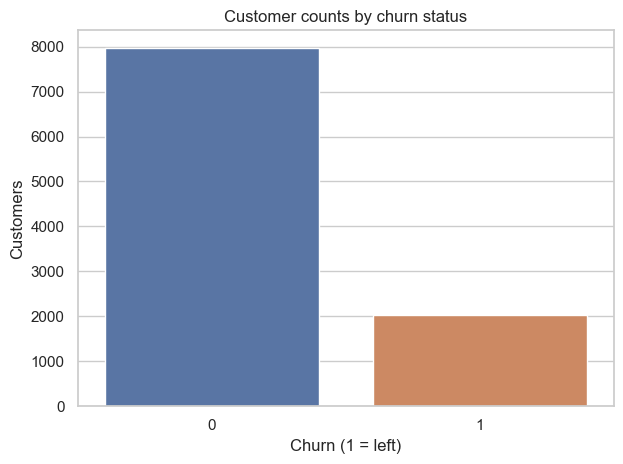

In [3]:
churn_summary = (
    data["churn"]
    .value_counts()
    .rename(index={0: "Stayed (0)", 1: "Churned (1)"})
    .rename("customers")
    .to_frame()
)
churn_summary["share"] = churn_summary["customers"] / len(data)
display(churn_summary)
print(f"Overall churn rate: {data['churn'].mean():.1%}")

ax = sns.countplot(data=data, x="churn", hue="churn", legend=False)
ax.set(title="Customer counts by churn status", xlabel="Churn (1 = left)", ylabel="Customers")
plt.tight_layout()
plt.show()

In [4]:
display(data.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
customer_id,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
credit_score,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
products_number,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
credit_card,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
active_member,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
estimated_salary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48
churn,10000.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00


Churn by country


,customers,churn_rate
country,,
Germany,2509,32.4%
Spain,2477,16.7%
France,5014,16.2%


Churn by gender


,customers,churn_rate
gender,,
Female,4543,25.1%
Male,5457,16.5%


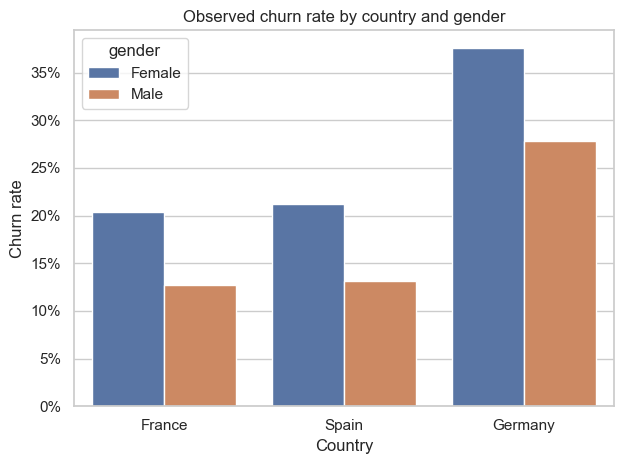

In [5]:
country_churn = (
    data.groupby("country", observed=True)["churn"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
gender_churn = (
    data.groupby("gender", observed=True)["churn"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
print("Churn by country")
display(country_churn.style.format({"churn_rate": "{:.1%}"}))
print("Churn by gender")
display(gender_churn.style.format({"churn_rate": "{:.1%}"}))

ax = sns.barplot(data=data, x="country", y="churn", hue="gender", errorbar=None)
ax.set(title="Observed churn rate by country and gender", xlabel="Country", ylabel="Churn rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()

Churn by number of products


,customers,churn_rate
products_number,,
1,5084,27.7%
2,4590,7.6%
3,266,82.7%
4,60,100.0%


,customers,churn_rate
age_group,,
Under 30,1641,7.6%
30-39,4346,10.9%
40-49,2618,30.8%
50-59,869,56.0%
60+,526,27.9%


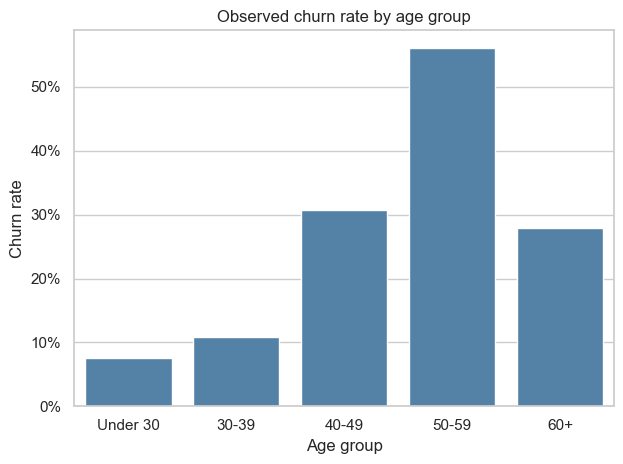

In [6]:
product_churn = (
    data.groupby("products_number", observed=True)["churn"]
    .agg(customers="size", churn_rate="mean")
)
print("Churn by number of products")
display(product_churn.style.format({"churn_rate": "{:.1%}"}))

data["age_group"] = pd.cut(
    data["age"],
    bins=[0, 30, 40, 50, 60, 100],
    right=False,
    labels=["Under 30", "30-39", "40-49", "50-59", "60+"],
)
age_churn = (
    data.groupby("age_group", observed=True)["churn"]
    .agg(customers="size", churn_rate="mean")
)
display(age_churn.style.format({"churn_rate": "{:.1%}"}))

ax = sns.barplot(data=data, x="age_group", y="churn", color="steelblue", errorbar=None)
ax.set(title="Observed churn rate by age group", xlabel="Age group", ylabel="Churn rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()

del data["age_group"]

### Initial observations

- The dataset contains 10,000 distinct customer IDs and no missing values or duplicate rows.
- Approximately one customer in five churned, so the target classes are imbalanced.
- Germany has a higher observed churn rate than France and Spain in this sample.
- Churn rates differ across gender, age, and product-count groups; all 60 customers with four products churned, so that small group should be interpreted cautiously. These patterns are descriptive and should not be interpreted as causal effects.

The modeling section uses a stratified split and reports churn-class precision, recall, and F1 alongside accuracy to make the class imbalance visible.

## 3. Prepare features and compare baseline models

The customer ID is excluded because it is an identifier. Numeric columns are scaled and categorical columns are one-hot encoded inside each model pipeline. This ensures preprocessing is learned from training data only, including within cross-validation.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X = data.drop(columns=["churn", "customer_id"])
y = data["churn"].astype(int)

categorical_features = ["country", "gender"]
numeric_features = [column for column in X.columns if column not in categorical_features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

def build_pipeline(estimator):
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", estimator),
        ]
    )

print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Churn rate ? train: {y_train.mean():.1%}; test: {y_test.mean():.1%}")

Training rows: 8,000; test rows: 2,000
Churn rate ? train: 20.4%; test: 20.3%


In [8]:
models = {
    "Logistic Regression": build_pipeline(
        LogisticRegression(max_iter=1_000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Decision Tree": build_pipeline(
        DecisionTreeClassifier(
            class_weight="balanced", min_samples_leaf=5, random_state=RANDOM_STATE
        )
    ),
    "Random Forest": build_pipeline(
        RandomForestClassifier(
            n_estimators=250,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),
}

baseline_rows = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    baseline_rows.append(
        {
            "model": model_name,
            "train_accuracy": accuracy_score(y_train, train_predictions),
            "test_accuracy": accuracy_score(y_test, test_predictions),
            "test_precision": precision_score(y_test, test_predictions, zero_division=0),
            "test_recall": recall_score(y_test, test_predictions, zero_division=0),
            "test_f1": f1_score(y_test, test_predictions, zero_division=0),
        }
    )

results_df = (
    pd.DataFrame(baseline_rows)
    .sort_values("test_f1", ascending=False)
    .reset_index(drop=True)
)
results_df.to_csv("results_df.csv", index=False)
display(results_df.style.format({column: "{:.3f}" for column in results_df.columns if column != "model"}))

,model,train_accuracy,test_accuracy,test_precision,test_recall,test_f1
0,Random Forest,1.000,0.860,0.773,0.442,0.562
1,Decision Tree,0.894,0.754,0.427,0.609,0.502
2,Logistic Regression,0.711,0.714,0.387,0.700,0.499


## 4. Tune a random forest

The randomized search optimizes F1 for the churn class using three-fold stratified cross-validation on the training set. The held-out test set is not used for model selection.

In [9]:
random_forest_pipeline = build_pipeline(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)
)
parameter_distributions = {
    "classifier__n_estimators": [150, 250],
    "classifier__max_depth": [None, 10, 16, 24],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.7],
    "classifier__class_weight": [None, "balanced_subsample"],
}

search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=parameter_distributions,
    n_iter=6,
    scoring="f1",
    cv=3,
    n_jobs=2,
    random_state=RANDOM_STATE,
    verbose=1,
    return_train_score=False,
)
search.fit(X_train, y_train)
print(f"Best cross-validation F1: {search.best_score_:.3f}")
print("Best parameters:")
print(search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits


Best cross-validation F1: 0.621
Best parameters:
{'classifier__n_estimators': 250, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}


In [10]:
best_model = search.best_estimator_
tuned_predictions = best_model.predict(X_test)

tuned_metrics = {
    "model": "Tuned Random Forest",
    "best_cv_f1": search.best_score_,
    "test_accuracy": accuracy_score(y_test, tuned_predictions),
    "test_precision": precision_score(y_test, tuned_predictions, zero_division=0),
    "test_recall": recall_score(y_test, tuned_predictions, zero_division=0),
    "test_f1": f1_score(y_test, tuned_predictions, zero_division=0),
    "best_parameters": str(search.best_params_),
}
tuned_results_df = pd.DataFrame([tuned_metrics])
tuned_results_df.to_csv("tuned_model_results.csv", index=False)
display(tuned_results_df.style.format({
    "best_cv_f1": "{:.3f}",
    "test_accuracy": "{:.3f}",
    "test_precision": "{:.3f}",
    "test_recall": "{:.3f}",
    "test_f1": "{:.3f}",
}))

print("Confusion matrix (rows = actual; columns = predicted):")
print(confusion_matrix(y_test, tuned_predictions))
print("\nClassification report:")
print(classification_report(y_test, tuned_predictions, target_names=["Stayed", "Churned"], zero_division=0))

,model,best_cv_f1,test_accuracy,test_precision,test_recall,test_f1,best_parameters
0,Tuned Random Forest,0.621,0.847,0.628,0.609,0.618,"{'classifier__n_estimators': 250, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}"


Confusion matrix (rows = actual; columns = predicted):
[[1446  147]
 [ 159  248]]

Classification report:
              precision    recall  f1-score   support

      Stayed       0.90      0.91      0.90      1593
     Churned       0.63      0.61      0.62       407

    accuracy                           0.85      2000
   macro avg       0.76      0.76      0.76      2000
weighted avg       0.85      0.85      0.85      2000



## 5. Conclusion

Use the baseline comparison and tuned-model test metrics above to assess the precision/recall trade-off for churn detection. A high accuracy score alone can be misleading when most customers stay. The final model was selected by cross-validation on the training set; the test metrics are a separate estimate on the held-out sample.

The results are educational and should be validated on additional, representative data before any operational use. Group-level differences in this dataset are associations, not explanations of why customers churn.